<a href="https://colab.research.google.com/github/Dulce946/M-todos-Numericos-1/blob/main/M%C3%A9todo%20del%20punto%20fijo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método del Punto Fijo (Algoritmo 2.2)
**Estudiante:** Dulce Maria Melchor Dávila

**Materia:** Métodos númericos

## Planteamos el problema

El objetivo del método del punto fijo es resolver ecuaciones de la forma:

$$f(x) = 0$$

## Ejemplo (Burden, pág. 38)
Consideremos la ecuación  algebraica:

$$f(x) = x^3 + 4x^2 - 10 = 0$$

De las multiples operaciones para despejar $x$ como $g(x)$, utilizaremos una de las operaciones convergentes analizadas dentro del intervalo $[1, 2]$:

$$g(x) = \sqrt{\frac{10}{4+x}}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Definición de la función de iteración g(x)
def g(x) :
    """
    Función de punto fijo derivada de x^3 + 4x^2 - 10 = 0.
    Garantiza convergencia en el intervalo [1, 2] ya que |g(x)| < 1.
    """
    return np.sqrt(10 / (4 + x))

#Definición de la función original f(x) para verificar visusalmente la raíz
def f(x):
    return x**3 + 4*x**2 - 10

## Implementación del algoritmo 2.2

El algoritmo requiere como parámetros de entrada:
1. Una aproximación inicial $p_0$.
2. Una tolerancia $TOL$.
3. Un número máximo de iteraciones $N_0$.

**Criterio de Parada:**  $|p - p_0| < TOL$.

In [4]:
def punto_fijo(g, p0, tol, max_iter):
    """
    Implementación fiel al algoritmo 2.2 del Burden.

    parámetros:
    g        : función continua g(x)
    p0       : aproximación inicial
    tol      : tolerancia admitida
    max_iter : número máximo de iteraciones (N0)
    """

    # Inicializar contador
    i = 1

    print(f"{'Iteración (i)':<15}{'p_0':<15}{'p = g(p_0)':<15}{'|p - p_0|':<15}")
    print("-" * 60)

    # Bucle iterativo controlado
    while i <= max_iter:
        # Calcular la siguiente aproximación
        p = g(p0)
        error_val = abs(p - p0)

        # Mostrar el proceso de la tabla de convergencia
        print(f"{i:<15}{p0:<15.9f}{p:<15.9f}{error_val:<15.9f}")

        # Comprobación del criterio de parada exitoso
        if error_val < tol:
            print("-" * 60)
            print(f"Éxito: Solución encontrada tras {i} iteraciones.")
            return p

        # Incrementar el contador
        i += 1

        # Actualizar para la siguiente iteración
        p0 = p

    # Mensaje en caso de no converger
    print("-" * 60)
    print(f"Error: El método falló después de {max_iter} iteraciones.")
    return None

##

## Pruebas y resultados

Ejecutamos el algoritmo con los siguientes valores iniciales típicos para este problema:
*  Aproximación inicial $p_0 = 1.5$
*  Tolerancia $TOL = 10^{-5}$
*  Máximo de iteraciones $N_0 = 30$

In [7]:
#Parámetros de prueba
p0_inicial = 1.5
tol = 1e-5
max_iteraciones = 30

#Llamada al método
solucion = punto_fijo(g, p0_inicial, tol, max_iteraciones)

if solucion is not None:
    print(f"La aproximación final encontrada para el punto fijo es: {solucion: .9f}")

Iteración (i)  p_0            p = g(p_0)     |p - p_0|      
------------------------------------------------------------
1              1.500000000    1.348399725    0.151600275    
2              1.348399725    1.367376372    0.018976647    
3              1.367376372    1.364957015    0.002419357    
4              1.364957015    1.365264748    0.000307733    
5              1.365264748    1.365225594    0.000039154    
6              1.365225594    1.365230576    0.000004982    
------------------------------------------------------------
Éxito: Solución encontrada tras 6 iteraciones.
La aproximación final encontrada para el punto fijo es:  1.365230576


## Validación de la gráfica
Visualizamos la intersección de $y = x$ con $y = g(x)$, la cual representa geométricamente el punto fijo.

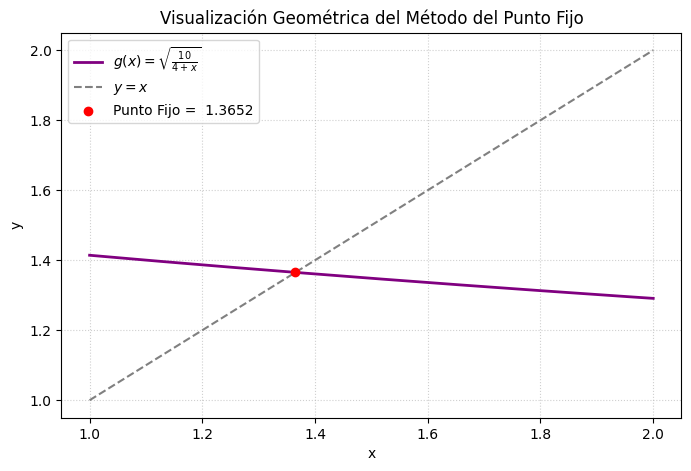

In [10]:
#Crear el rango de valores para x en el intervalo de interés
x_vals = np.linspace(1, 2, 200)
y_g = g(x_vals)
y_x = x_vals               #Línea identidad y = x

plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_g, label=r'$g(x) = \sqrt{\frac{10}{4+x}}$', color='purple', lw=2)
plt.plot(x_vals, y_x, label=r'$y = x$', color='gray', linestyle='--')

#Si encontramos solución, la graficamos como un punto
if solucion is not None:
    plt.scatter(solucion, solucion, color='red', zorder=5, label=f'Punto Fijo = {solucion: .4f}')

plt.title('Visualización Geométrica del Método del Punto Fijo')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()